# 4.3.1 Source Domains: Study Area Maps

Generates the thesis figures:

- **Figure 4.2**: Location of the three source domains (Indonesia, Kerala, Thailand)
- **Figure 4.3**: Indonesia study area
- **Figure 4.4**: Kerala study area
- **Figure 4.5**: Thailand study area

Boundaries: [Natural Earth](https://www.naturalearthdata.com/) (public domain). Figures are saved at 300 dpi.

## 1. Install and import

In [1]:
# Run once if needed
# !pip install geopandas matplotlib pandas requests

In [2]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

os.makedirs("figures", exist_ok=True)

## 2. Load boundary data (downloads on first run)

In [3]:
COUNTRIES_URL = "https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip"
STATES_URL = "https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_1_states_provinces.zip"

countries = gpd.read_file(COUNTRIES_URL)
states = gpd.read_file(STATES_URL)

indonesia = countries[countries["ADMIN"] == "Indonesia"]
thailand = countries[countries["ADMIN"] == "Thailand"]
kerala = states[(states["admin"] == "India") & (states["name"] == "Kerala")]

print(len(indonesia), len(thailand), len(kerala))  # each should be 1

1 1 1


## 3. (Optional) Your study sites

Create `study_sites.csv` next to this notebook with columns `name, lon, lat, domain`,
where `domain` is `Indonesia`, `Kerala` or `Thailand`. If the file is absent, maps are drawn without points.

In [4]:
SITES_CSV = "study_sites.csv"
sites = None
if os.path.exists(SITES_CSV):
    df = pd.read_csv(SITES_CSV)
    sites = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.lon, df.lat), crs="EPSG:4326")
    print(sites.groupby("domain").size())
else:
    print("No study_sites.csv found; drawing maps without site points.")

No study_sites.csv found; drawing maps without site points.


## 4. Style and helper functions

In [5]:
COL = {"Indonesia": "#d95f02", "Kerala": "#1b9e77", "Thailand": "#7570b3"}
LAND, SEA, EDGE = "#efefef", "#dbe9f4", "#8c8c8c"
DPI = 300
plt.rcParams.update({"font.family": "serif", "font.size": 10})


def north_arrow(ax, x=0.94, y=0.92, size=0.07):
    ax.annotate("", xy=(x, y), xytext=(x, y - size), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.5))
    ax.text(x, y + 0.01, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=11, fontweight="bold")


def scale_bar(ax, length_km, loc=(0.06, 0.06)):
    """Approximate scale bar for a lon/lat axis."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    lat = y0 + (y1 - y0) * loc[1]
    km_per_deg = 111.32 * np.cos(np.radians((y0 + y1) / 2))
    deg = length_km / km_per_deg
    xs = x0 + (x1 - x0) * loc[0]
    ax.plot([xs, xs + deg], [lat, lat], color="black", lw=3, solid_capstyle="butt")
    ax.text(xs + deg / 2, lat + (y1 - y0) * 0.015, f"{length_km:,} km",
            ha="center", va="bottom", fontsize=8)


def base_axes(figsize, extent):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_facecolor(SEA)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect(1 / np.cos(np.radians((extent[2] + extent[3]) / 2)))
    ax.grid(color="white", lw=0.6, alpha=0.8)
    ax.set_xlabel("Longitude (°E)")
    ax.set_ylabel("Latitude (°N)")
    return fig, ax


def plot_sites(ax, domain):
    if sites is not None:
        s = sites[sites["domain"] == domain]
        if len(s):
            s.plot(ax=ax, color="black", markersize=18, zorder=6, label="Study sites")


def save(fig, name):
    path = os.path.join("figures", name)
    fig.savefig(path, dpi=DPI, bbox_inches="tight", facecolor="white")
    plt.show()
    print("saved", path)

## 5. Figure 4.2: Location of the three source domains

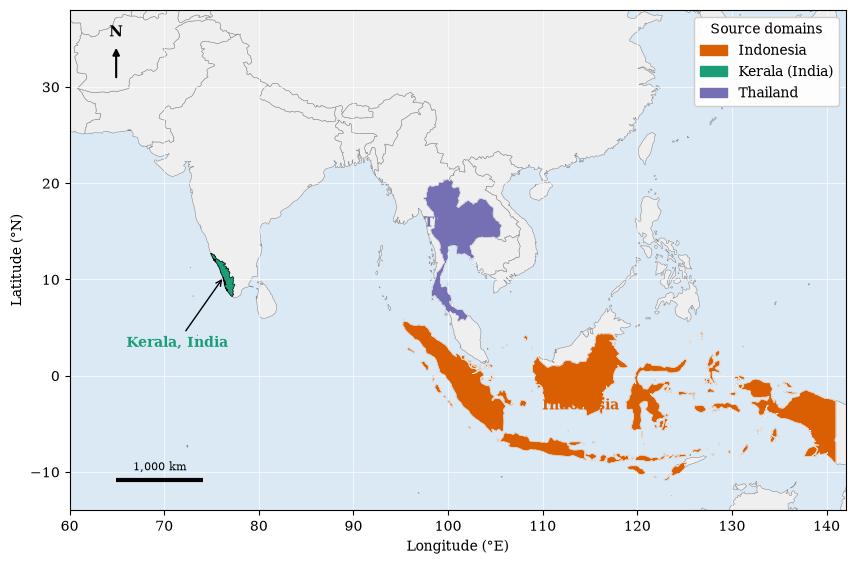

saved figures\fig_4_2_source_domains.png


In [6]:
extent = (60, 142, -14, 38)   # (min_lon, max_lon, min_lat, max_lat)
fig, ax = base_axes((11, 6.5), extent)

countries.plot(ax=ax, color=LAND, edgecolor=EDGE, lw=0.4)
indonesia.plot(ax=ax, color=COL["Indonesia"], edgecolor="white", lw=0.4, zorder=3)
thailand.plot(ax=ax, color=COL["Thailand"], edgecolor="white", lw=0.4, zorder=3)
kerala.plot(ax=ax, color=COL["Kerala"], edgecolor="black", lw=0.5, zorder=4)

# Kerala is small at this scale, so use a callout
ax.annotate("Kerala, India", xy=(76.3, 10.3), xytext=(66, 3),
            arrowprops=dict(arrowstyle="->", color="black"),
            fontsize=10, fontweight="bold", color=COL["Kerala"])
ax.text(101, 15.5, "Thailand", fontsize=10, fontweight="bold", color=COL["Thailand"], ha="center")
ax.text(114, -3.5, "Indonesia", fontsize=10, fontweight="bold", color=COL["Indonesia"], ha="center")

handles = [Patch(color=COL[k], label="Kerala (India)" if k == "Kerala" else k) for k in COL]
ax.legend(handles=handles, title="Source domains", loc="upper right", framealpha=0.95)
north_arrow(ax, x=0.06, y=0.93)
scale_bar(ax, 1000)
save(fig, "fig_4_2_source_domains.png")

## 6. Reusable function for the individual study-area maps

In [7]:
def domain_map(target, title, extent, admin1_country, scale_km, figsize, fname, key, label_admin1=False):
    fig, ax = base_axes(figsize, extent)
    countries.plot(ax=ax, color=LAND, edgecolor=EDGE, lw=0.5)
    if admin1_country:
        sub = states[states["admin"] == admin1_country]
        sub.plot(ax=ax, facecolor="none", edgecolor="#777777", lw=0.3, zorder=2)
    target.plot(ax=ax, color=COL[key], alpha=0.55, edgecolor="black", lw=0.8, zorder=3)
    if label_admin1 and admin1_country:
        for _, r in sub.iterrows():
            c = r.geometry.representative_point()
            if extent[0] < c.x < extent[1] and extent[2] < c.y < extent[3]:
                ax.text(c.x, c.y, r["name"], fontsize=6, ha="center", zorder=5)
    plot_sites(ax, key)
    ax.set_title(title, fontweight="bold")
    north_arrow(ax)
    scale_bar(ax, scale_km)
    if sites is not None and (sites["domain"] == key).any():
        ax.legend(loc="lower right")
    save(fig, fname)

## 7. Figure 4.3: Indonesia

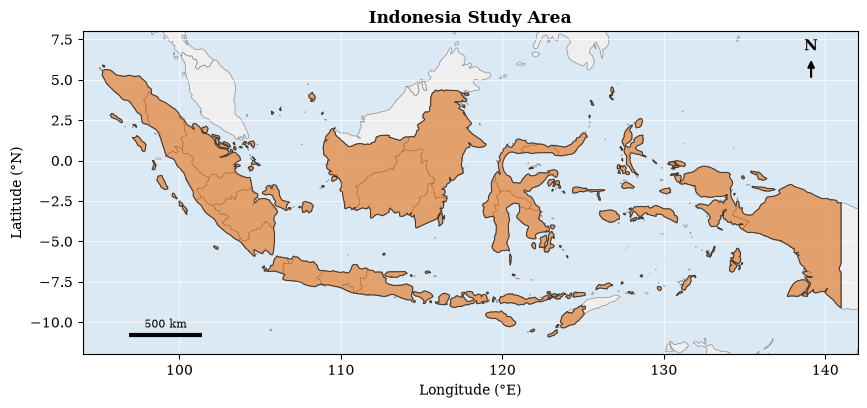

saved figures\fig_4_3_indonesia.png


In [8]:
domain_map(indonesia, "Indonesia Study Area", (94, 142, -12, 8),
           "Indonesia", 500, (10, 5), "fig_4_3_indonesia.png", "Indonesia")

## 8. Figure 4.4: Kerala

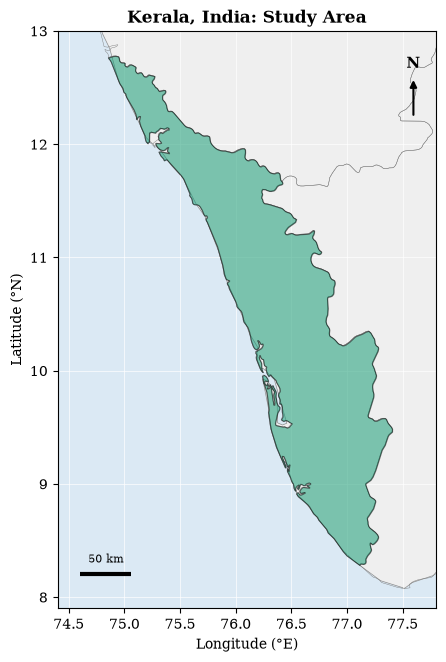

saved figures\fig_4_4_kerala.png


In [9]:
domain_map(kerala, "Kerala, India: Study Area", (74.4, 77.8, 7.9, 13.0),
           "India", 50, (5, 7.5), "fig_4_4_kerala.png", "Kerala")

## 9. Figure 4.5: Thailand

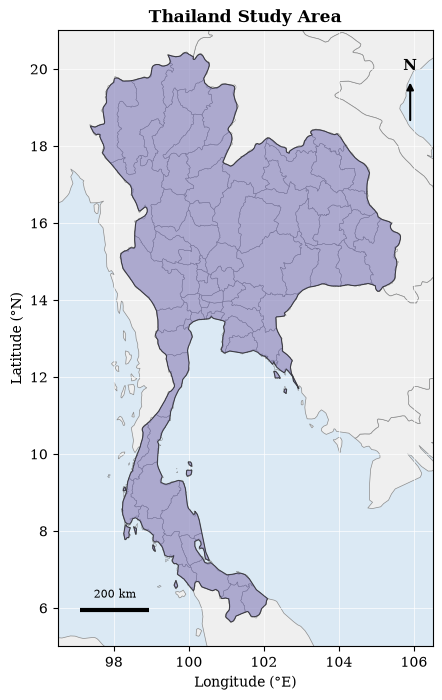

saved figures\fig_4_5_thailand.png


In [10]:
domain_map(thailand, "Thailand Study Area", (96.5, 106.5, 5.0, 21.0),
           "Thailand", 200, (5.5, 8), "fig_4_5_thailand.png", "Thailand")

Raster exists: True
Landslide points exist: True
Study area bounds: [110.8986786   -8.28516641 111.42672879  -7.91852782]
Number of landslide points: 743
Indonesia boundary loaded: True


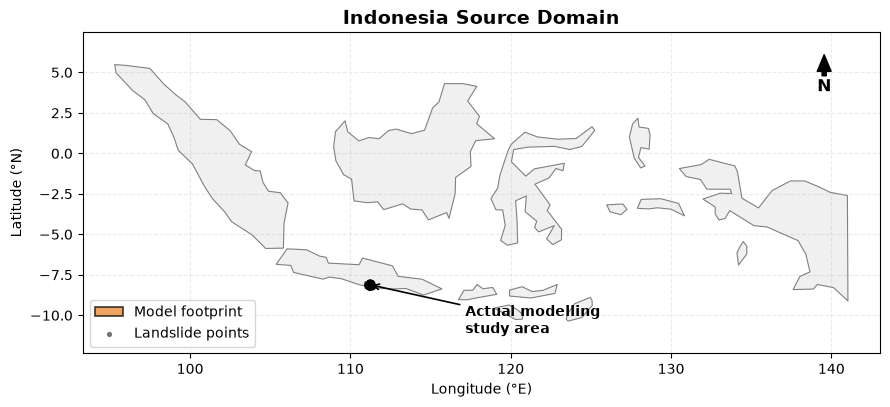

Saved to: D:\PROJECTS\Landslide_prediction\indonesia_source_domain_context.png


In [4]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import rasterio
from shapely.geometry import box

# ---------------------------------------------------------
# 1. Project paths
# ---------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"

INDONESIA_ELEV_RASTER = (
    DATA_RAW
    / "cempaka_indonesia"
    / "Landslide Controlling Factors"
    / "map_elev.tif"
)

INDONESIA_LANDSLIDES = (
    DATA_RAW
    / "cempaka_indonesia"
    / "Landslide Point"
    / "ls_center.gpkg"
)

print("Raster exists:", INDONESIA_ELEV_RASTER.exists())
print("Landslide points exist:", INDONESIA_LANDSLIDES.exists())


# ---------------------------------------------------------
# 2. Create modelling-footprint polygon from raster extent
# ---------------------------------------------------------

with rasterio.open(INDONESIA_ELEV_RASTER) as src:
    bounds = src.bounds
    raster_crs = src.crs

study_area = gpd.GeoDataFrame(
    {"name": ["Indonesia Source Domain"]},
    geometry=[box(bounds.left, bounds.bottom, bounds.right, bounds.top)],
    crs=raster_crs
).to_crs("EPSG:4326")

print("Study area bounds:", study_area.total_bounds)


# ---------------------------------------------------------
# 3. Load landslide points (optional)
# ---------------------------------------------------------

if INDONESIA_LANDSLIDES.exists():
    landslides = gpd.read_file(INDONESIA_LANDSLIDES).to_crs("EPSG:4326")
    print("Number of landslide points:", len(landslides))
else:
    landslides = None


# ---------------------------------------------------------
# 4. Load Indonesia country boundary from Natural Earth
# ---------------------------------------------------------

# ---------------------------------------------------------
# 4. Load Indonesia country boundary from Natural Earth
# ---------------------------------------------------------

NATURAL_EARTH_URL = (
    "https://naturalearth.s3.amazonaws.com/"
    "110m_cultural/ne_110m_admin_0_countries.zip"
)

world = gpd.read_file(NATURAL_EARTH_URL)
world = world.to_crs("EPSG:4326")

# Natural Earth normally uses ADMIN for country name
if "ADMIN" in world.columns:
    indonesia = world[world["ADMIN"] == "Indonesia"].copy()
elif "NAME" in world.columns:
    indonesia = world[world["NAME"] == "Indonesia"].copy()
elif "name" in world.columns:
    indonesia = world[world["name"] == "Indonesia"].copy()
else:
    raise KeyError(
        "Could not find the country-name column. "
        f"Available columns: {world.columns.tolist()}"
    )

print("Indonesia boundary loaded:", not indonesia.empty)


# ---------------------------------------------------------
# 5. Plot
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 8))

# Country background
indonesia.plot(
    ax=ax,
    color="#f0f0f0",
    edgecolor="gray",
    linewidth=0.8,
    zorder=1
)

# Study area footprint
study_area.plot(
    ax=ax,
    color="#e67e22",
    edgecolor="black",
    linewidth=1.3,
    alpha=0.7,
    zorder=3,
    label="Model footprint"
)

# Optional landslide points
if landslides is not None:
    landslides.plot(
        ax=ax,
        color="black",
        markersize=8,
        alpha=0.45,
        zorder=4,
        label="Landslide points"
    )


# ---------------------------------------------------------
# 6. Add label / callout
# ---------------------------------------------------------

centroid = study_area.geometry.iloc[0].centroid

ax.annotate(
    "Actual modelling\nstudy area",
    xy=(centroid.x, centroid.y),
    xytext=(centroid.x + 6, centroid.y - 3),
    arrowprops=dict(arrowstyle="->", color="black", lw=1.2),
    fontsize=10,
    fontweight="bold"
)


# ---------------------------------------------------------
# 7. Add north arrow
# ---------------------------------------------------------

ax.annotate(
    "N",
    xy=(0.93, 0.93),
    xytext=(0.93, 0.83),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(
        facecolor="black",
        width=3,
        headwidth=10
    )
)


# ---------------------------------------------------------
# 8. Set extent around Indonesia
# ---------------------------------------------------------

minx, miny, maxx, maxy = indonesia.total_bounds
ax.set_xlim(minx - 2, maxx + 2)
ax.set_ylim(miny - 2, maxy + 2)


# ---------------------------------------------------------
# 9. Formatting
# ---------------------------------------------------------

ax.set_title(
    "Indonesia Source Domain",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

ax.grid(True, linestyle="--", alpha=0.25)

ax.legend(loc="lower left")

plt.tight_layout()


# ---------------------------------------------------------
# 10. Save
# ---------------------------------------------------------

OUTPUT = PROJECT_ROOT / "indonesia_source_domain_context.png"

plt.savefig(
    OUTPUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", OUTPUT)

Boundary file: D:\PROJECTS\Landslide_prediction\data\raw\lka_admin_boundaries.gdb
Exists: True


C:\Users\PCC\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts.  The processing may be really slow.  You can skip the processing by setting METHOD=SKIP.
  return ogr_read(


Number of districts: 25
['Colombo', 'Gampaha', 'Kalutara', 'Kandy', 'Matale', 'Nuwara Eliya', 'Galle', 'Matara', 'Hambantota', 'Jaffna', 'Mannar', 'Vavuniya', 'Mullaitivu', 'Kilinochchi', 'Batticaloa', 'Ampara', 'Trincomalee', 'Kurunegala', 'Puttalam', 'Anuradhapura', 'Polonnaruwa', 'Badulla', 'Monaragala', 'Ratnapura', 'Kegalle']

Selected target districts:
['Kandy', 'Nuwara Eliya', 'Badulla', 'Kegalle']


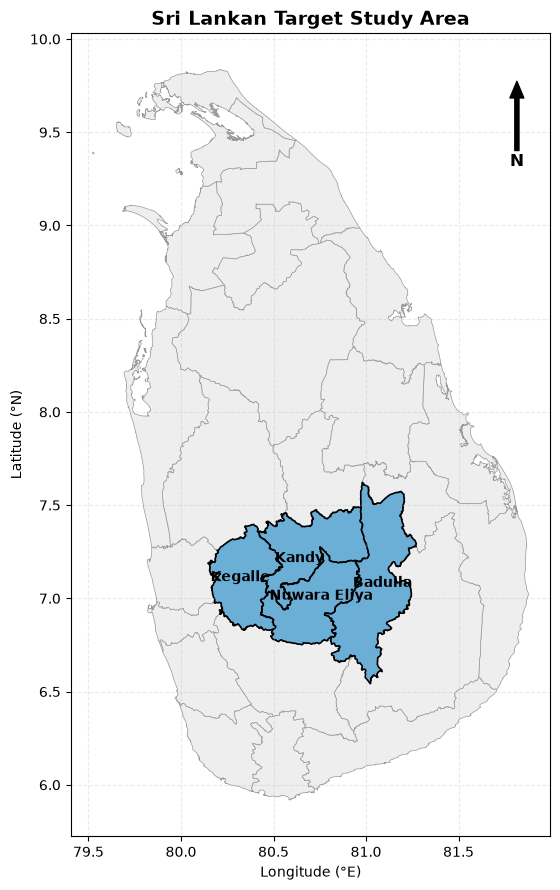

Saved to: D:\PROJECTS\Landslide_prediction\sri_lanka_target_study_area.png


In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. File path
# ---------------------------------------------------------

# Adjust this only if your project location is different
PROJECT_ROOT = Path.cwd().resolve().parent

DATA_RAW = PROJECT_ROOT / "data" / "raw"

BOUNDARY_FILE = DATA_RAW / "lka_admin_boundaries.gdb"

print("Boundary file:", BOUNDARY_FILE)
print("Exists:", BOUNDARY_FILE.exists())


# ---------------------------------------------------------
# 2. Load Sri Lankan district boundaries
# ---------------------------------------------------------

districts = gpd.read_file(
    BOUNDARY_FILE,
    layer="lka_admin2"
)

# Make sure coordinates are longitude/latitude
districts = districts.to_crs("EPSG:4326")

print("Number of districts:", len(districts))
print(districts["adm2_name"].tolist())


# ---------------------------------------------------------
# 3. Select the FOUR target districts
# ---------------------------------------------------------

TARGET_DISTRICTS = [
    "Kandy",
    "Nuwara Eliya",
    "Kegalle",
    "Badulla"
]

target = districts[
    districts["adm2_name"].isin(TARGET_DISTRICTS)
].copy()

print("\nSelected target districts:")
print(target["adm2_name"].tolist())


# ---------------------------------------------------------
# 4. Check that all four districts were found
# ---------------------------------------------------------

assert len(target) == 4, (
    f"Expected 4 districts but found {len(target)}. "
    "Check district names."
)


# ---------------------------------------------------------
# 5. Create the map
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 9))

# Whole Sri Lanka - background
districts.plot(
    ax=ax,
    color="#eeeeee",
    edgecolor="#999999",
    linewidth=0.5
)

# Four study districts
target.plot(
    ax=ax,
    color="#6baed6",
    edgecolor="black",
    linewidth=1.2
)


# ---------------------------------------------------------
# 6. Add district labels
# ---------------------------------------------------------

for _, row in target.iterrows():
    point = row.geometry.representative_point()

    ax.text(
        point.x,
        point.y,
        row["adm2_name"],
        fontsize=10,
        fontweight="bold",
        ha="center",
        va="center"
    )


# ---------------------------------------------------------
# 7. Add north arrow
# ---------------------------------------------------------

ax.annotate(
    "N",
    xy=(0.93, 0.94),
    xytext=(0.93, 0.84),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=12,
    fontweight="bold",
    arrowprops=dict(
        facecolor="black",
        width=3,
        headwidth=10
    )
)


# ---------------------------------------------------------
# 8. Formatting
# ---------------------------------------------------------

ax.set_title(
    "Sri Lankan Target Study Area",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")

ax.grid(
    True,
    linestyle="--",
    alpha=0.25
)

plt.tight_layout()


# ---------------------------------------------------------
# 9. Save high-resolution map
# ---------------------------------------------------------

OUTPUT = PROJECT_ROOT / "sri_lanka_target_study_area.png"

plt.savefig(
    OUTPUT,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved to:", OUTPUT)

## Notes for the thesis

- Suggested caption: *Figure 4.2: Location of the three source domains (Indonesia, Kerala in India, and Thailand). Boundaries: Natural Earth.*
- `extent` is `(min_lon, max_lon, min_lat, max_lat)`. Adjust to zoom.
- For finer boundaries (e.g. districts), swap `states` for GADM shapefiles.
- The scale bar is approximate; reproject to a local UTM CRS if you need a rigorous one.